<a href="https://colab.research.google.com/github/Alex-So-Ma/Data_Analysis/blob/main/Proyecto_Introducci%C3%B3n_al_An%C3%A1lisis_Exploratorio_de_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Proyecto Introducción al Análisis Exploratorio de Datos**

El objetivo de este proyecto es aplicar los conocimientos adquiridos durante el módulo en curso en la introducción al análisis de datos, basados íntegramente en el material expuesto en las sesiones y las lecturas correspondientes. Se espera que demuestres tu competencia en las siguientes áreas clave:

*Recopilación de Datos: Identificar y cargar un dataset de fuente pública, describiendo su origen, contexto y estructura inicial.

*Limpieza de Datos: Diagnosticar el estado del dataset, tratar los valores nulos de variables de texto y numéricas, normalizar columnas categóricas, convertir tipos de dato y exportar el dataset limpio como insumo para las etapas posteriores.

*Exploración de Datos: Generar el resumen estadístico, visualizar distribuciones, detectar y filtrar valores atípicos con el método del Rango Intercuartílico (IQR), y analizar correlaciones entre variables numéricas.

*Visualización de Datos: Construir una narrativa visual coherente con gráficos diseñados para comunicar los hallazgos más relevantes del dataset a una audiencia no técnica.

In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#Dataset

https://www.kaggle.com/datasets/sachinpatil1280/fifa-world-cup


El dataset es la información de los partidos de la Copa Mundial de Fútbol de la FIFA. Esto de las ediciones de 1930 a 2014. Se econtró este conjunto de datos en Kaggle.

In [ ]:
drive.mount('/content/drive')

ruta_colab = '/content/drive/MyDrive/Curso AD/Tercer módulo/Introducción al Análisis Exploratorio de Datos/FIFA_World_Cup_1558_23.csv'
df_original = pd.read_csv(ruta_colab)

df_original

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Unnamed: 0,Year,Datetime,Stage,Stadium,City,Home.Team.Name,Home.Team.Goals,Away.Team.Goals,Away.Team.Name,...,Attendance,Half.time.Home.Goals,Half.time.Away.Goals,Referee,Assistant.1,Assistant.2,RoundID,MatchID,Home.Team.Initials,Away.Team.Initials
0,1,1930,13 Jul 1930 - 15:00,Group 1,Pocitos,Montevideo,France,4,1,Mexico,...,4444,3,0,LOMBARDI Domingo (URU),CRISTOPHE Henry (BEL),REGO Gilberto (BRA),201,1096,FRA,MEX
1,2,1930,13 Jul 1930 - 15:00,Group 4,Parque Central,Montevideo,USA,3,0,Belgium,...,18346,2,0,MACIAS Jose (ARG),MATEUCCI Francisco (URU),WARNKEN Alberto (CHI),201,1090,USA,BEL
2,3,1930,14 Jul 1930 - 12:45,Group 2,Parque Central,Montevideo,Yugoslavia,2,1,Brazil,...,24059,2,0,TEJADA Anibal (URU),VALLARINO Ricardo (URU),BALWAY Thomas (FRA),201,1093,YUG,BRA
3,4,1930,14 Jul 1930 - 14:50,Group 3,Pocitos,Montevideo,Romania,3,1,Peru,...,2549,1,0,WARNKEN Alberto (CHI),LANGENUS Jean (BEL),MATEUCCI Francisco (URU),201,1098,ROU,PER
4,5,1930,15 Jul 1930 - 16:00,Group 1,Parque Central,Montevideo,Argentina,1,0,France,...,23409,0,0,REGO Gilberto (BRA),SAUCEDO Ulises (BOL),RADULESCU Constantin (ROU),201,1085,ARG,FRA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
845,848,2014,05 Jul 2014 - 17:00,Quarter-finals,Arena Fonte Nova,Salvador,Netherlands,0,0,Costa Rica,...,51179,0,0,Ravshan IRMATOV (UZB),RASULOV Abduxamidullo (UZB),KOCHKAROV Bakhadyr (KGZ),255953,300186488,NED,CRC
846,849,2014,08 Jul 2014 - 17:00,Semi-finals,Estadio Mineirao,Belo Horizonte,Brazil,1,7,Germany,...,58141,0,5,RODRIGUEZ Marco (MEX),TORRENTERA Marvin (MEX),QUINTERO Marcos (MEX),255955,300186474,BRA,GER
847,850,2014,09 Jul 2014 - 17:00,Semi-finals,Arena de Sao Paulo,Sao Paulo,Netherlands,0,0,Argentina,...,63267,0,0,C�neyt �AKIR (TUR),DURAN Bahattin (TUR),ONGUN Tarik (TUR),255955,300186490,NED,ARG
848,851,2014,12 Jul 2014 - 17:00,Play-off for third place,Estadio Nacional,Brasilia,Brazil,0,3,Netherlands,...,68034,0,2,HAIMOUDI Djamel (ALG),ACHIK Redouane (MAR),ETCHIALI Abdelhak (ALG),255957,300186502,BRA,NED


#Limpeza de Datos

In [ ]:
df = df_original.copy() #Creamos una copia del dataframe original

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 850 entries, 0 to 849
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Unnamed: 0            850 non-null    int64 
 1   Year                  850 non-null    int64 
 2   Datetime              850 non-null    object
 3   Stage                 850 non-null    object
 4   Stadium               850 non-null    object
 5   City                  850 non-null    object
 6   Home.Team.Name        850 non-null    object
 7   Home.Team.Goals       850 non-null    int64 
 8   Away.Team.Goals       850 non-null    int64 
 9   Away.Team.Name        850 non-null    object
 10  Win.conditions        850 non-null    object
 11  Attendance            850 non-null    int64 
 12  Half.time.Home.Goals  850 non-null    int64 
 13  Half.time.Away.Goals  850 non-null    int64 
 14  Referee               850 non-null    object
 15  Assistant.1           850 non-null    ob

No nos interese los nombres de los árbitros para este proyecto, solo nos vamos a quedar con sus países. Una vez agregamos sus países a columnas nuevas quitamos columnas que no necesitamos, mejor dicho, que no vamos a usar:

*Unnamed no tiene ninguna información importante, es como tener los ídices en una columna del dataframe.

*Datetime tampoco nos intersa, nos uinteresa más el año, que ya tiene su propia columna.

*Win.conditions es una columna con muchos valores nulos, aunque no aparezacan como tal, ya que son espacios los valores que tomamos como nulos. Además de ser oraciones muy variadas, no datos concretos como tal, los que si tiene información.

*Stadium y City es como los nombres de los árbitros, son tantos y tan variados que con el año, en este caso, es suficiente.

*RoundID y MatchID solo son valores de identificación.

*Referee, Assistant.1 y Assistant.2 ya está explicado

In [ ]:
df['Referee.ctry'] = df['Referee'].str[-4:-1]
df['Assistant.1.ctry'] = df['Assistant.1'].str[-4:-1]
df['Assistant.2.ctry'] = df['Assistant.2'].str[-4:-1]

In [ ]:
df=df.drop(columns=['Unnamed: 0','Datetime','Win.conditions', 'Stadium',	'City', 'RoundID', 'MatchID', 'Referee', 'Assistant.1', 'Assistant.2'])

Ahora vamos a revisar registros duplicados y eliminarlos.

In [ ]:
df[df.duplicated()]

,Year,Stage,Home.Team.Name,Home.Team.Goals,Away.Team.Goals,Away.Team.Name,Attendance,Half.time.Home.Goals,Half.time.Away.Goals,Home.Team.Initials,Away.Team.Initials,Referee.ctry,Assistant.1.ctry,Assistant.2.ctry
835,2014,Round of 16,Brazil,1,1,Chile,57714,0,0,BRA,CHI,ENG,ENG,ENG
836,2014,Round of 16,Colombia,2,0,Uruguay,73804,1,0,COL,URU,NED,NED,NED
837,2014,Round of 16,Netherlands,2,1,Mexico,58817,0,0,NED,MEX,POR,POR,POR
838,2014,Round of 16,Costa Rica,1,1,Greece,41242,0,0,CRC,GRE,AUS,AUS,AUS
839,2014,Round of 16,France,2,0,Nigeria,67882,0,0,FRA,NGA,USA,USA,CAN
840,2014,Round of 16,Argentina,1,0,Switzerland,63255,0,0,ARG,SUI,SWE,SWE,SWE
841,2014,Round of 16,Belgium,2,1,USA,51227,0,0,BEL,USA,ALG,MAR,ALG
842,2014,Quarter-finals,France,0,1,Germany,74240,0,1,FRA,GER,ARG,ARG,ARG
843,2014,Quarter-finals,Brazil,2,1,Colombia,60342,1,0,BRA,COL,ESP,ESP,ESP
844,2014,Quarter-finals,Argentina,1,0,Belgium,68551,1,0,ARG,BEL,ITA,ITA,ITA


In [ ]:
df = df.drop_duplicates()
df[df.duplicated()]

,Year,Stage,Home.Team.Name,Home.Team.Goals,Away.Team.Goals,Away.Team.Name,Attendance,Half.time.Home.Goals,Half.time.Away.Goals,Home.Team.Initials,Away.Team.Initials,Referee.ctry,Assistant.1.ctry,Assistant.2.ctry


Ahora verificamos los valores nulos y vemos que no hay.

In [ ]:
print(df.isnull().sum())

Year                    0
Stage                   0
Home.Team.Name          0
Home.Team.Goals         0
Away.Team.Goals         0
Away.Team.Name          0
Attendance              0
Half.time.Home.Goals    0
Half.time.Away.Goals    0
Home.Team.Initials      0
Away.Team.Initials      0
Referee.ctry            0
Assistant.1.ctry        0
Assistant.2.ctry        0
dtype: int64


Ahora con los datos existentes en el dataframe vamos a crear columnas que nos digan que equipo fue el ganador y cual el perdedor, al final del partido y al medio tiempo.

In [ ]:
# Diferencia de goles al final del partido (positivo = gana local, negativo = gana visitante)
df['final_difference'] = df['Home.Team.Goals'] - df['Away.Team.Goals']

# Equipo ganador y perdedor según la diferencia final
df['winning_team'] = df.apply(lambda row: row['Home.Team.Initials'] if row['final_difference'] > 0
                              else (row['Away.Team.Initials'] if row['final_difference'] < 0
                              else 'Draw'), axis=1)

df['losing_team'] = df.apply(lambda row: row['Home.Team.Initials'] if row['final_difference'] < 0
                             else (row['Away.Team.Initials'] if row['final_difference'] > 0
                             else 'Draw'), axis=1)

# Mismo concepto pero al medio tiempo
df['half_time_difference'] = df['Half.time.Home.Goals'] - df['Half.time.Away.Goals']

df['winning_team_at_half_time'] = df.apply(lambda row: row['Home.Team.Initials'] if row['half_time_difference'] > 0
                                           else (row['Away.Team.Initials'] if row['half_time_difference'] < 0
                                           else 'Draw'), axis=1)

Cree un dataframe con información adicional, que saque de wikipedia, sobre las confederaciones de cada país. Esto con la intención de agregar esta información en nuevas columnas.

In [ ]:
pasies_confederaciones = [
    ('NIG', 'Níger', 'CAF'),
    ('SEY', 'Seychelles', 'CAF'),
    ('GAM', 'Gambia', 'CAF'),
    ('BER', 'Bermuda', 'CONCACAF'),
    ('HKG', 'Hong Kong', 'AFC'),
    ('MRI', 'Mauricio', 'CAF'),
    ('THA', 'Tailandia', 'AFC'),
    ('UZB', 'Uzbekistán', 'AFC'),
    ('FIN', 'Finlandia', 'UEFA'),
    ('CUW', 'Curazao', 'CONCACAF'),
    ('ETH', 'Etiopía', 'CAF'),
    ('SIN', 'Singapur', 'AFC'),
    ('VEN', 'Venezuela', 'CONMEBOL'),
    ('ERI', 'Eritrea', 'CAF'),
    ('SYR', 'Siria', 'AFC'),
    ('LBY', 'Libia', 'CAF'),
    ('BHR', 'Baréin', 'AFC'),
    ('GUA', 'Guatemala', 'CONCACAF'),
    ('MLI', 'Malí', 'CAF'),
    ('GAB', 'Gabón', 'CAF'),
    ('BAH', 'Bahamas', 'CONCACAF'),
    ('SRI', 'Sri Lanka', 'AFC'),
    ('BLR', 'Bielorrusia', 'UEFA'),
    ('MLT', 'Malta', 'UEFA'),
    ('MAS', 'Malasia', 'AFC'),
    ('OMA', 'Omán', 'AFC'),
    ('VAN', 'Vanuatu', 'OFC'),
    ('ATG', 'Antigua y Barbuda', 'CONCACAF'),
    ('JOR', 'Jordania', 'AFC'),
    ('MDV', 'Maldivas', 'AFC'),
    ('ZIM', 'Zimbabue', 'CAF'),
    ('LIB', 'Líbano', 'AFC'),
    ('UGA', 'Uganda', 'CAF'),
    ('IND', 'India', 'AFC'),
    ('BEN', 'Benín', 'CAF'),
    ('KGZ', 'Kirguistán', 'AFC'),
    ('TGA', 'Tonga', 'OFC'),
    ('BDI', 'Burundi', 'CAF'),
    ('RWA', 'Ruanda', 'CAF'),
    ('MEX', 'México', 'CONCACAF'),
    ('BEL', 'Bélgica', 'UEFA'),
    ('BRA', 'Brasil', 'CONMEBOL'),
    ('PER', 'Perú', 'CONMEBOL'),
    ('FRA', 'Francia', 'UEFA'),
    ('BOL', 'Bolivia', 'CONMEBOL'),
    ('PAR', 'Paraguay', 'CONMEBOL'),
    ('ROU', 'Rumanía', 'UEFA'),
    ('CHI', 'Chile', 'CONMEBOL'),
    ('USA', 'Estados Unidos', 'CONCACAF'),
    ('YUG', 'Yugoslavia', 'UEFA'),
    ('ARG', 'Argentina', 'CONMEBOL'),
    ('EGY', 'Egipto', 'CAF'),
    ('NED', 'Países Bajos', 'UEFA'),
    ('SUI', 'Suiza', 'UEFA'),
    ('SWE', 'Suecia', 'UEFA'),
    ('ESP', 'España', 'UEFA'),
    ('HUN', 'Hungría', 'UEFA'),
    ('AUT', 'Austria', 'UEFA'),
    ('GER', 'Alemania', 'UEFA'),
    ('TCH', 'Checoslovaquia', 'UEFA'),
    ('INH', 'Indias Orientales Neerlandesas', 'AFC'),
    ('NOR', 'Noruega', 'UEFA'),
    ('POL', 'Polonia', 'UEFA'),
    ('CUB', 'Cuba', 'CONCACAF'),
    ('ITA', 'Italia', 'UEFA'),
    ('ENG', 'Inglaterra', 'UEFA'),
    ('SCO', 'Escocia', 'UEFA'),
    ('TUR', 'Turquía', 'UEFA'),
    ('KOR', 'Corea del Sur', 'AFC'),
    ('FRG', 'Alemania Occidental', 'UEFA'),
    ('URU', 'Uruguay', 'CONMEBOL'),
    ('WAL', 'Gales', 'UEFA'),
    ('NIR', 'Irlanda del Norte', 'UEFA'),
    ('URS', 'Unión Soviética', 'UEFA'),
    ('COL', 'Colombia', 'CONMEBOL'),
    ('BUL', 'Bulgaria', 'UEFA'),
    ('PRK', 'Corea del Norte', 'AFC'),
    ('POR', 'Portugal', 'UEFA'),
    ('ISR', 'Israel', 'UEFA'),
    ('MAR', 'Marruecos', 'CAF'),
    ('SLV', 'El Salvador', 'CONCACAF'),
    ('AUS', 'Australia', 'AFC'),
    ('HAI', 'Haití', 'CONCACAF'),
    ('GDR', 'Alemania Oriental', 'UEFA'),
    ('ZAI', 'Zaire', 'CAF'),
    ('IRN', 'Irán', 'AFC'),
    ('TUN', 'Túnez', 'CAF'),
    ('CMR', 'Camerún', 'CAF'),
    ('NZL', 'Nueva Zelanda', 'OFC'),
    ('ALG', 'Argelia', 'CAF'),
    ('HON', 'Honduras', 'CONCACAF'),
    ('KUW', 'Kuwait', 'AFC'),
    ('IRQ', 'Iraq', 'AFC'),
    ('DEN', 'Dinamarca', 'UEFA'),
    ('CAN', 'Canadá', 'CONCACAF'),
    ('IRL', 'República de Irlanda', 'UEFA'),
    ('UAE', 'Emiratos Árabes Unidos', 'AFC'),
    ('CRC', 'Costa Rica', 'CONCACAF'),
    ('KSA', 'Arabia Saudita', 'AFC'),
    ('RUS', 'Rusia', 'UEFA'),
    ('GRE', 'Grecia', 'UEFA'),
    ('NGA', 'Nigeria', 'CAF'),
    ('RSA', 'Sudáfrica', 'CAF'),
    ('JPN', 'Japón', 'AFC'),
    ('CRO', 'Croacia', 'UEFA'),
    ('JAM', 'Jamaica', 'CONCACAF'),
    ('SEN', 'Senegal', 'CAF'),
    ('SVN', 'Eslovenia', 'UEFA'),
    ('ECU', 'Ecuador', 'CONMEBOL'),
    ('CHN', 'China', 'AFC'),
    ('CIV', 'Costa de Marfil', 'CAF'),
    ('CZE', 'República Checa', 'UEFA'),
    ('GHA', 'Ghana', 'CAF'),
    ('TOG', 'Togo', 'CAF'),
    ('UKR', 'Ucrania', 'UEFA'),
    ('TRI', 'Trinidad y Tobago', 'CONCACAF'),
    ('SCG', 'Serbia y Montenegro', 'UEFA'),
    ('ANG', 'Angola', 'CAF'),
    ('SVK', 'Eslovaquia', 'UEFA'),
    ('SRB', 'Serbia', 'UEFA'),
    ('BIH', 'Bosnia y Herzegovina', 'UEFA'),
]

df_confederaciones = pd.DataFrame(pasies_confederaciones, columns=['Initials', 'Name', 'Confederation'])

In [ ]:
# Creamos el diccionario de confederaciones una sola vez
conf_dict = df_confederaciones.set_index('Initials')['Confederation'].to_dict()

# Confederación del equipo ganador y perdedor
# Si no hay match (ej: 'Draw') conservamos el valor original con fillna
df['winning_team_confederation'] = df['winning_team'].map(conf_dict).fillna(df['winning_team'])
df['losing_team_confederation'] = df['losing_team'].map(conf_dict).fillna(df['losing_team'])

# Confederación del árbitro y asistentes según su país
df['referee_confederation'] = df['Referee.ctry'].map(conf_dict)
df['Assistant.1_confederation'] = df['Assistant.1.ctry'].map(conf_dict)
df['Assistant.2_confederation'] = df['Assistant.2.ctry'].map(conf_dict)

Se cambia los: group 1, group 2, group A, etc. a group stage.

In [ ]:
for i in df.index:
    if df['Stage'][i][0] == 'G':
        df.loc[i, 'Stage'] = 'Group stage'

Limpiamos los datos en texto que dejamos y cambiamos el tipo de dato de la columna Year a category.

In [ ]:
# Observar valores únicos
countries = []

for i in ['Stage', 'Home.Team.Name', 'Away.Team.Name']:
  print(i, '\n', df[i].unique(), '\n')

Stage 
 ['Group stage' 'Semi-finals' 'Final' 'Preliminary round' 'Quarter-finals'
 'Match for third place' 'First round' 'Round of 16' 'Third place'
 'Play-off for third place'] 

Home.Team.Name 
 ['France' 'USA' 'Yugoslavia' 'Romania' 'Argentina' 'Chile' 'Uruguay'
 'Brazil' 'Paraguay' 'Austria' 'Hungary' 'Switzerland' 'Sweden' 'Germany'
 'Spain' 'Italy' 'Czechoslovakia' 'Cuba' 'England' 'Germany FR' 'Turkey'
 'Soviet Union' 'Northern Ireland' 'Mexico' 'Wales' 'Portugal' 'Korea DPR'
 'Peru' 'Belgium' 'Bulgaria' 'German DR' 'Zaire' 'Poland' 'Australia'
 'Scotland' 'Netherlands' 'Haiti' 'Tunisia' 'Algeria' 'Honduras' 'Canada'
 'Morocco' 'Korea Republic' 'Iraq' 'Denmark' 'rn">United Arab Emirates'
 'Costa Rica' 'Cameroon' 'rn">Republic of Ireland' 'Colombia' 'Norway'
 'Nigeria' 'Saudi Arabia' 'Bolivia' 'Russia' 'Greece' 'Jamaica'
 'South Africa' 'Japan' 'Croatia' 'China PR' 'Senegal' 'Slovenia'
 'Ecuador' 'rn">Trinidad and Tobago' 'rn">Serbia and Montenegro' 'Angola'
 'Czech Republic' 'To

In [ ]:
# Limpia el texto: quita caracteres especiales y convierte a minúsculas
def limpiar_texto(texto):
    import re
    if pd.isna(texto): return texto
    texto = re.sub(r'[^a-zA-ZáéíóúÁÉÍÓÚñÑ\s]', '', str(texto))
    return texto.lower()

# Aplicamos la limpieza a las columnas de texto
for col in ['Home.Team.Name', 'Away.Team.Name', 'Stage']:
    df[col] = df[col].apply(limpiar_texto)

In [ ]:
df['Year'] = df['Year'].astype('category')

In [ ]:
# Crear dataset final
df.to_csv("FIFA_World_Cup_1558_23_clean.csv", index=False)

#Exploración de Datos

In [ ]:
columnas_numericas = ['Home.Team.Goals', 'Away.Team.Goals', 'Attendance', 'Half.time.Home.Goals', 'Half.time.Away.Goals', 'final_difference', 'half_time_difference']
df[columnas_numericas].describe()

,Home.Team.Goals,Away.Team.Goals,Attendance,Half.time.Home.Goals,Half.time.Away.Goals,final_difference,half_time_difference
count,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000
mean,1.823952,1.021557,44859.457485,0.719760,0.427545,0.802395,0.292216
std,1.620137,1.072667,23551.107893,0.942231,0.675333,1.929947,1.144636
min,0.000000,0.000000,2000.000000,0.000000,0.000000,-7.000000,-5.000000
25%,1.000000,0.000000,29800.000000,0.000000,0.000000,0.000000,0.000000
50%,2.000000,1.000000,41000.000000,0.000000,0.000000,1.000000,0.000000
75%,3.000000,2.000000,61009.000000,1.000000,1.000000,2.000000,1.000000
max,10.000000,7.000000,173850.000000,6.000000,5.000000,9.000000,6.000000


Generamos histogramas y diagramas de caja de las variables numéricas.

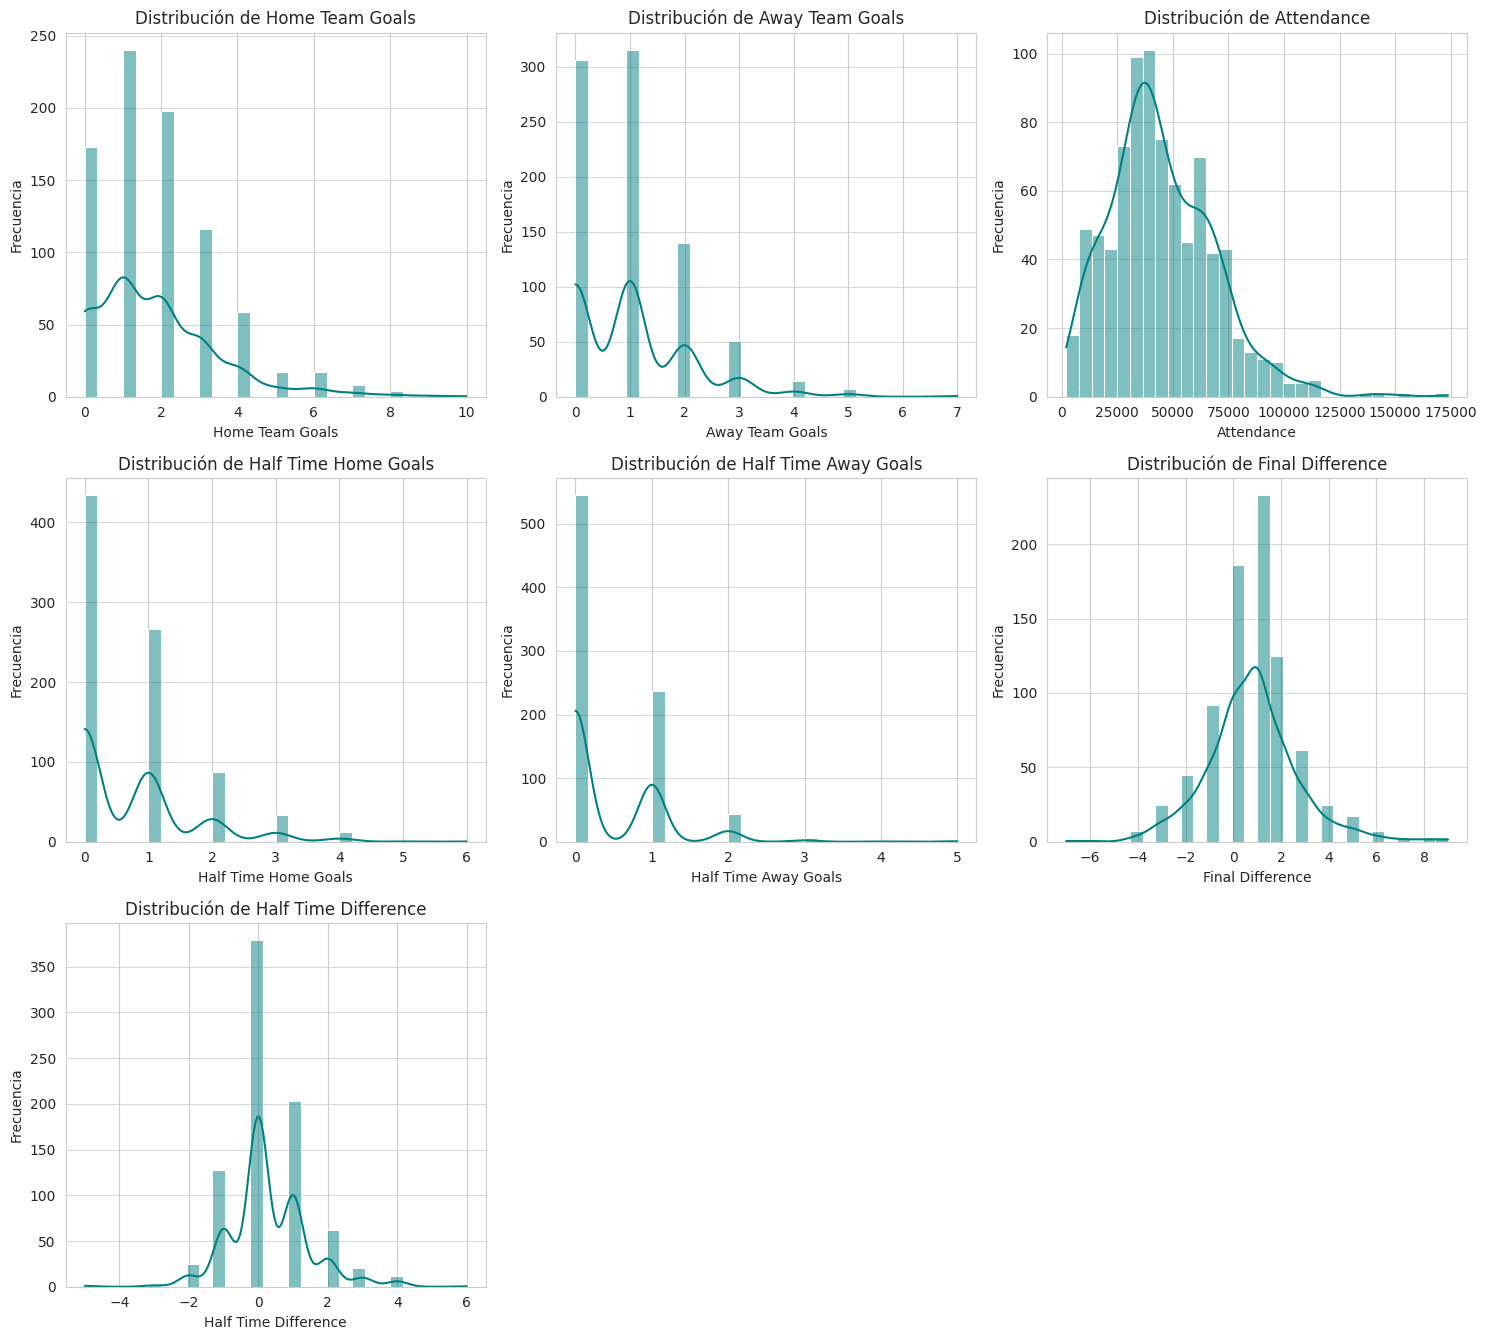

In [ ]:
plt.figure(figsize=(15, 13.5))

# Un histograma por cada columna numérica, con curva KDE encima
for i, col in enumerate(columnas_numericas, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[col], bins=30, kde=True, color='teal')

    # Limpiamos el nombre de la columna para el título
    nombre = col.replace("_", " ").replace(".", " ").title()
    plt.title(f'Distribución de {nombre}')
    plt.xlabel(nombre)
    plt.ylabel('Frecuencia')
    plt.grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.show()

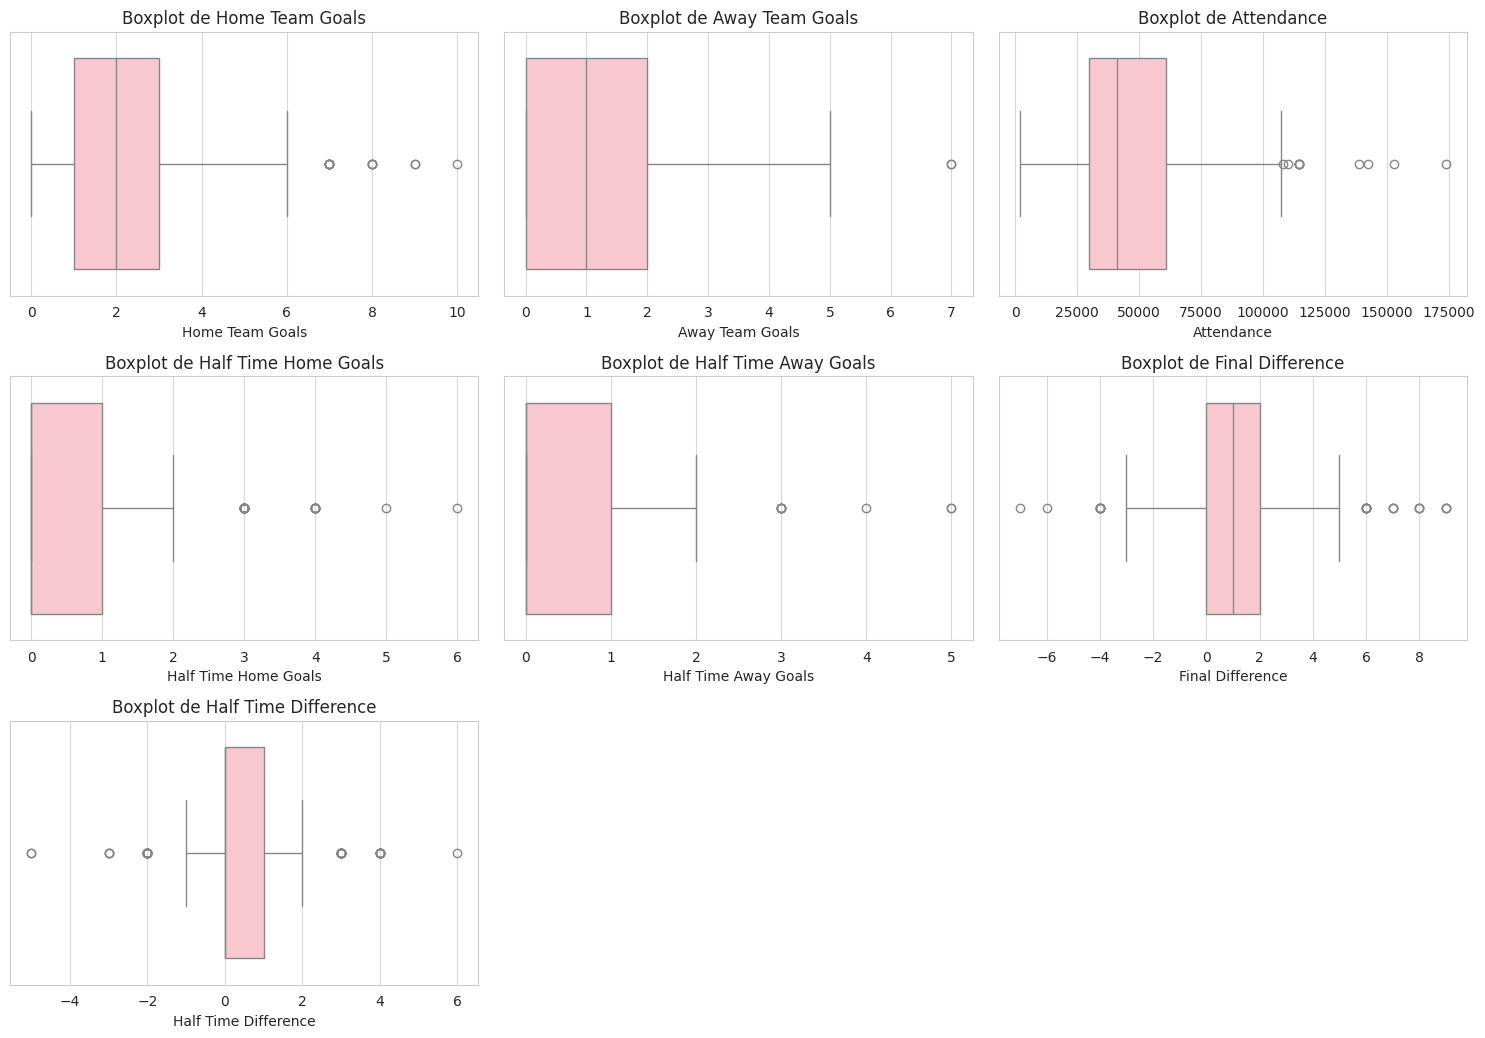

In [ ]:
plt.figure(figsize=(15, 13.5))

# Boxplot por cada columna numérica para ver outliers y distribución
for i, col in enumerate(columnas_numericas, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(x=df[col], color='pink')

    nombre = col.replace("_", " ").replace(".", " ").title()
    plt.title(f'Boxplot de {nombre}')
    plt.xlabel(nombre)
    plt.grid(axis='x', alpha=0.75)

plt.tight_layout()
plt.show()

El propósito de esta sección es:

Calcular el rango intercuartílico y filtrar el dataframe con los registros dentro de los límites.

Calcular la cantidad y proporción de registros finales y graficar su diagrama de caja.

Sin embargo, dada la natruraleza de los datos al final decidí que no es prudente eliminar datos, ya que no veo la necesidad de elimar outliers que sucenden o se presentan por como se dan las condicones del torneo.

In [ ]:
print(f"Cantidad de datos iniciales: {len(df)}")

Cantidad de datos iniciales: 835


In [ ]:
# Calculo del IQR

df_copy = df.copy() # preservar el dataset haciendo una copia

for col in columnas_numericas:

    Q1 = df_copy[col].quantile(0.25) # Primer cuartil
    Q3 = df_copy[col].quantile(0.75) # Tercer cuartil
    IQR = Q3 - Q1 # Rango Intercuartilico

    lim_inf_iqr = Q1 - 1.5 * IQR # Límite inferior
    lim_sup_iqr = Q3 + 1.5 * IQR # Límite superior

    cant_inicial = len(df_copy)
    # Filtro de los datos dentro de los límites
    df_copy = df_copy[(df_copy[col] >= lim_inf_iqr) & (df_copy[col] <= lim_sup_iqr)]
    cant_final = len(df_copy)

    print(f"Columna '{col}': Se eliminaron {cant_inicial - cant_final} registros.")

Columna 'Home.Team.Goals': Se eliminaron 15 registros.
Columna 'Away.Team.Goals': Se eliminaron 2 registros.
Columna 'Attendance': Se eliminaron 10 registros.
Columna 'Half.time.Home.Goals': Se eliminaron 35 registros.
Columna 'Half.time.Away.Goals': Se eliminaron 6 registros.
Columna 'final_difference': Se eliminaron 8 registros.
Columna 'half_time_difference': Se eliminaron 20 registros.


In [ ]:
# Ver cantidad y proporción con la cantidad inicial
prop_cant_datos = round((len(df_copy) / len(df)) * 100, 2)

print(f"Cantidad de datos finales: {len(df_copy)}")
print(f"Los datos finales representan el {prop_cant_datos}% de los datos iniciales")

Cantidad de datos finales: 739
Los datos finales representan el 88.5% de los datos iniciales


Aquí hago quer df_copy vuelva a ser al copia sin alterar del dataframe, ya que la decisión de no quitar los outliers la tompé después.

In [ ]:
df_copy = df.copy()

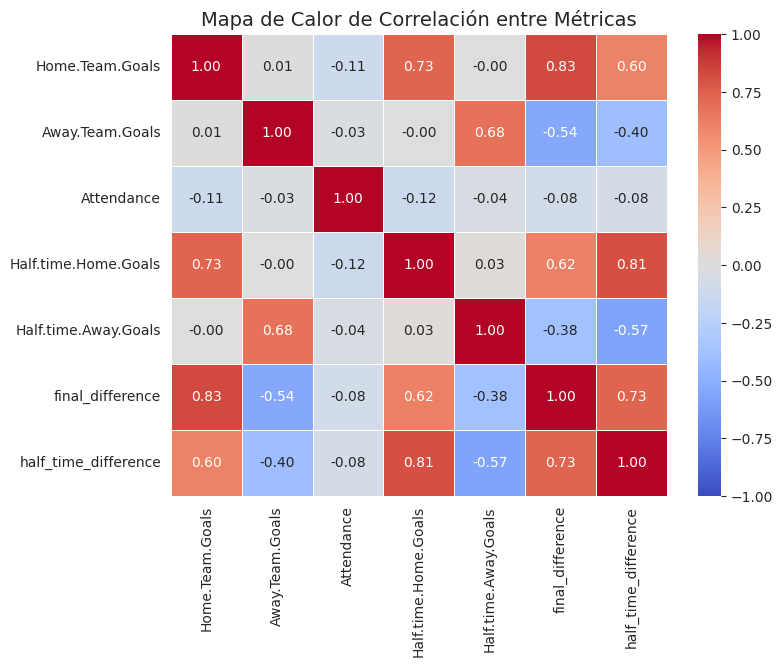

In [ ]:
# Realizar matriz de correlación
corr_matrix = df_copy[columnas_numericas].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)

plt.title('Mapa de Calor de Correlación entre Métricas', fontsize=14)
plt.show()

/tmp/ipykernel_27801/1543245431.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for room, grupo in df_copy.groupby(segmentacion):


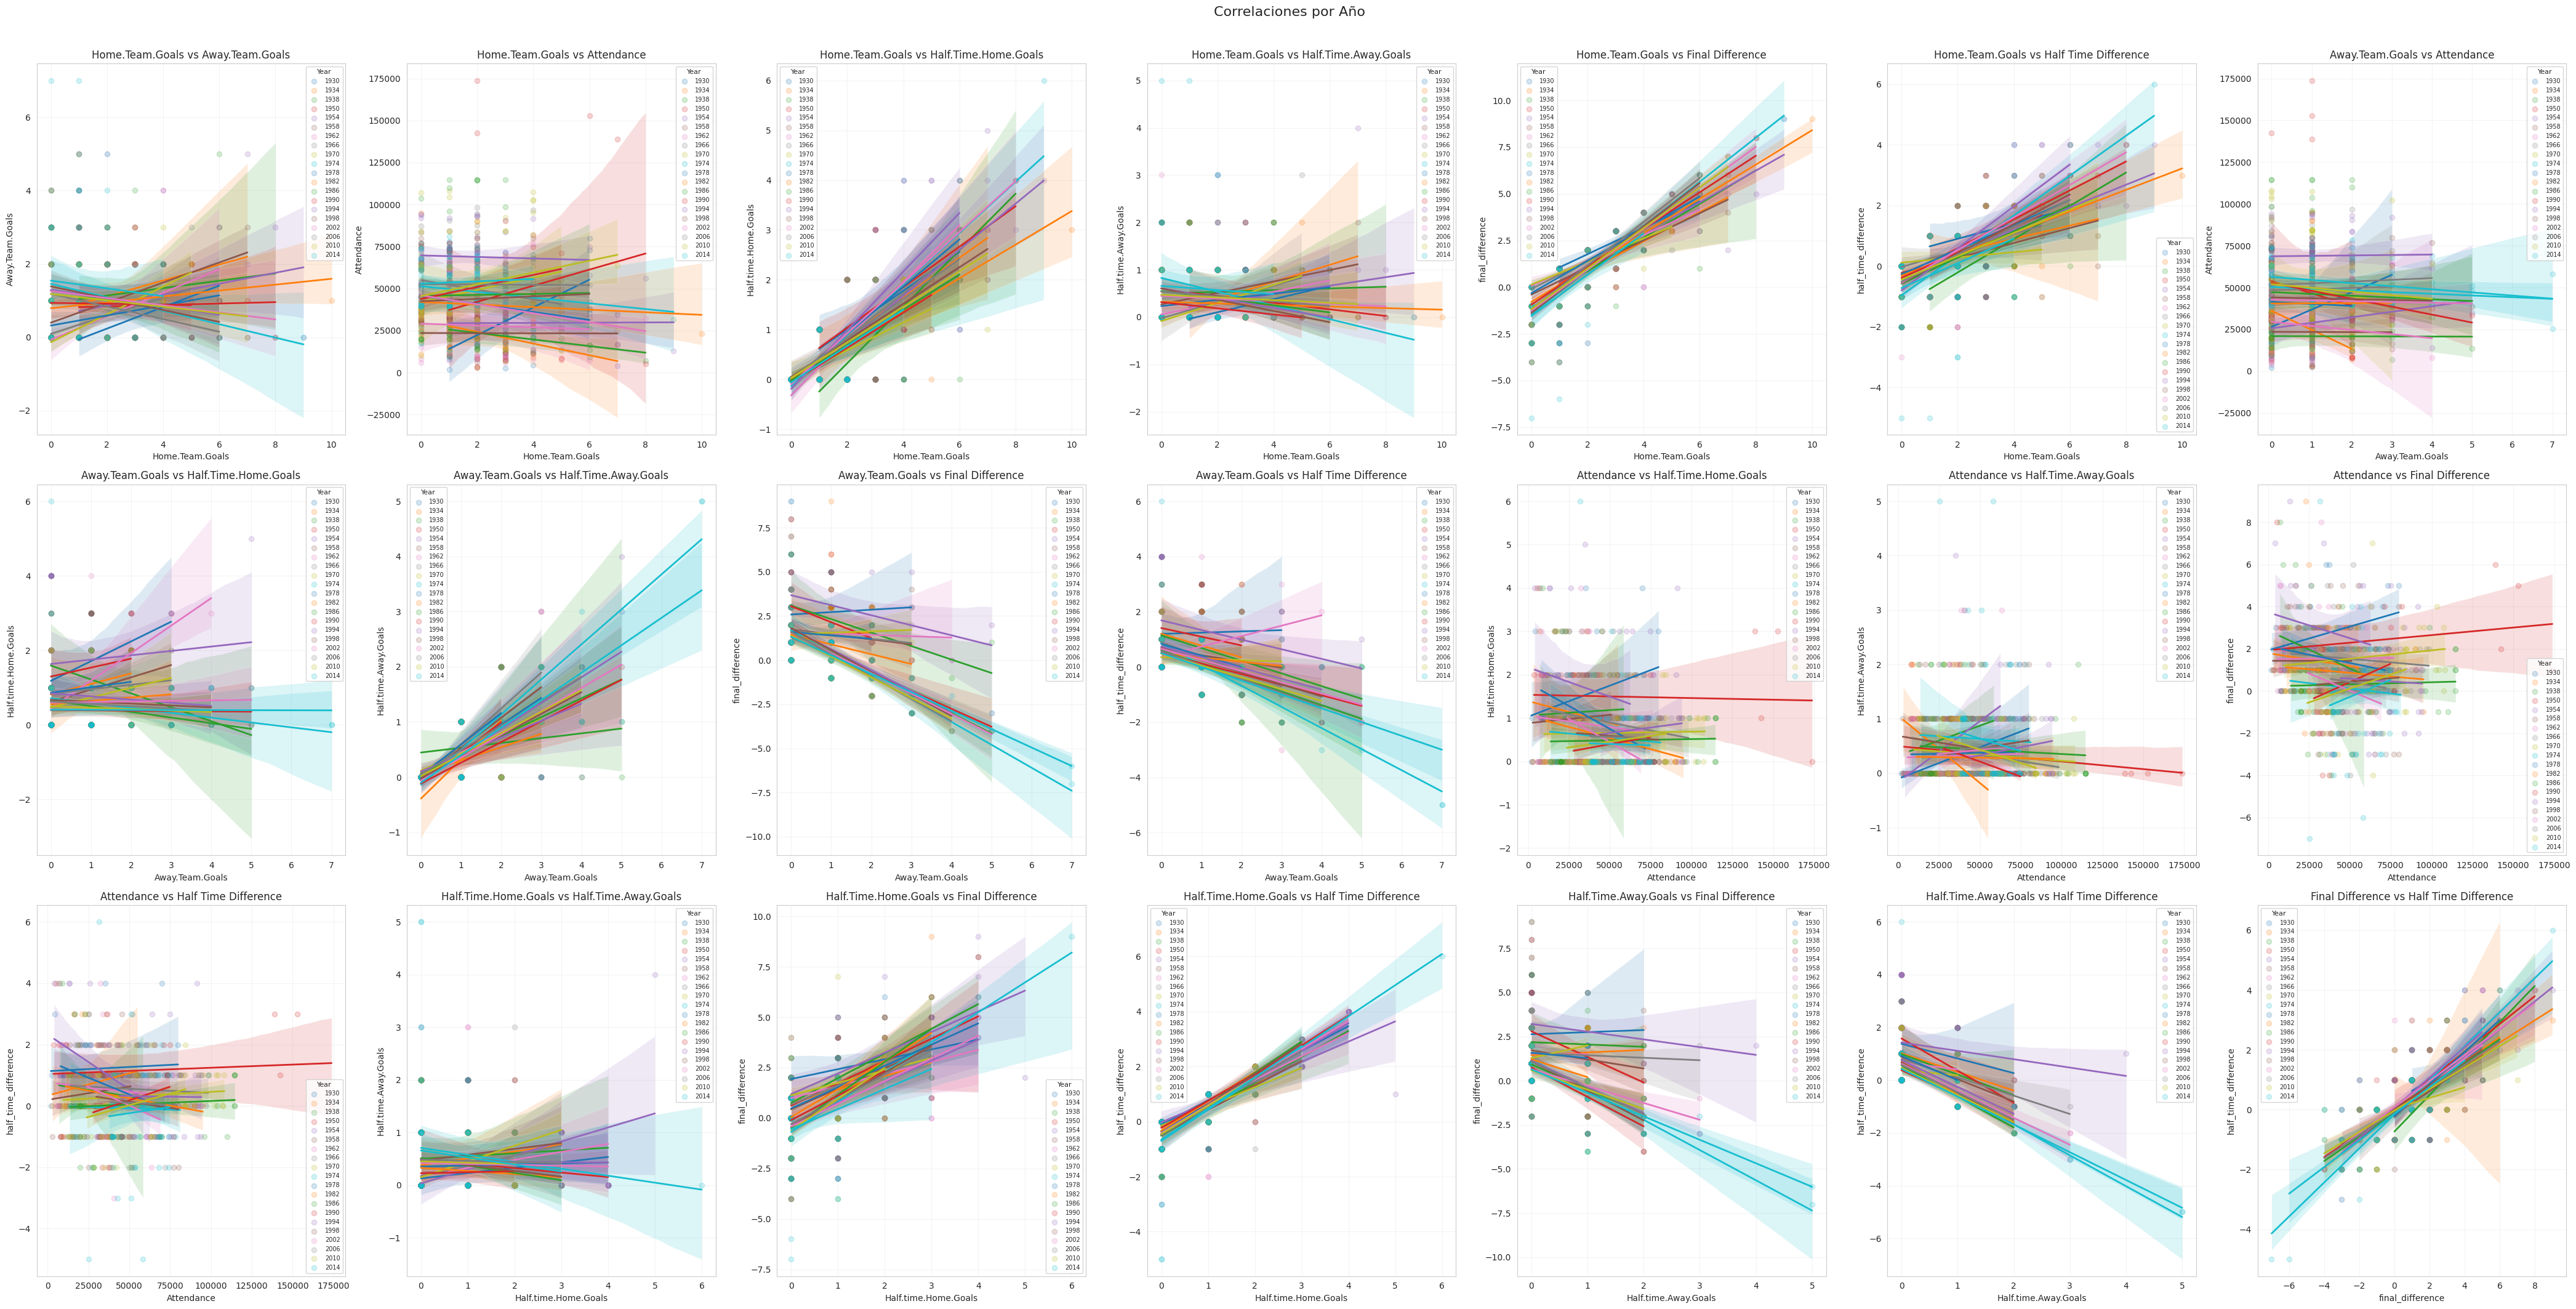

In [ ]:
import itertools

segmentacion = 'Year'

# Generamos todos los pares posibles de columnas numéricas sin repetición
# Con 7 columnas obtenemos exactamente 21 combinaciones, que llenan la cuadrícula 3x7
comparaciones = list(itertools.combinations(columnas_numericas, 2))

# Creamos la figura con cuadrícula 3x7 (exacta para 21 combinaciones)
fig, axes = plt.subplots(nrows=3, ncols=7, figsize=(42, 21))
axes = axes.flatten()  # Convertimos la matriz 2D de subplots en array 1D para iterar fácilmente

# Obtenemos los años únicos y asignamos un color distinto a cada uno
años = df_copy[segmentacion].unique()
palette = dict(zip(años, sns.color_palette("tab10", len(años))))

# Iteramos sobre cada par de variables y su subplot correspondiente
for i, (col_x, col_y) in enumerate(comparaciones):

    # Para cada par, dibujamos una línea de regresión por cada año
    for año, grupo in df_copy.groupby(segmentacion):
        sns.regplot(
            ax=axes[i],          # Subplot donde se dibuja
            data=grupo,          # Solo los datos del año actual
            x=col_x, y=col_y,
            scatter_kws={'alpha': 0.2, 'color': palette[año]},  # Puntos semitransparentes
            line_kws={'color': palette[año], 'linewidth': 2},   # Línea de regresión del mismo color
            label=año            # Etiqueta para la leyenda
        )

    # Reemplazamos guiones bajos y aplicamos mayúsculas
    axes[i].set_title(f'{col_x.replace("_", " ").title()} vs {col_y.replace("_", " ").title()}')
    axes[i].grid(True, alpha=0.2)  # Cuadrícula suave para facilitar la lectura
    axes[i].legend(title=segmentacion, fontsize=7, title_fontsize=8)  # Leyenda compacta

plt.suptitle('Correlaciones por Año', fontsize=16, y=1.01)  # Título general de la figura
plt.tight_layout()  # Ajusta espacios entre subplots automáticamente
plt.show()

Escogemos final_difference y half_time_difference, a pesar de no ser los de mayor correlación, por lo interesante de la correlación en sí. Este correalción confirma, que en general, se espera que el ganador al medio tiempo sea el ganador final.

In [ ]:
# Cálculo de la regresión lineal simple
y=df_copy['final_difference']
x=df_copy['half_time_difference']
linear_regression = np.polyfit(x, y, 1)
beta, alpha = linear_regression

print(f'y = {beta} x + {alpha}')

y = 1.232924230932788 x + 0.44211555407473047


In [ ]:
# Calculo del descenso de gradiente
tamaño_paso = 0.01
theta_0 = 0
theta_1 = 0

perdida = []

n=len(df_copy['half_time_difference'])

num_iteraciones = 2000

for i in range(num_iteraciones):
    y_pred = theta_1 * x + theta_0
    error = ((y_pred - y) ** 2).mean()
    perdida.append(error)

    d_theta_0 = (2 / n) * np.sum(y_pred - y)
    d_theta_1 = (2 / n) * np.sum((y_pred - y) * x)

    theta_0 = theta_0 - tamaño_paso * d_theta_0
    theta_1 = theta_1 - tamaño_paso * d_theta_1

print(f'y = {theta_1} x + {theta_0}')

y = 1.2329242309327841 x + 0.4421155540747327


De la regresión lineal y del descenso del gradiente, vemos que en general se espera que el resultado al medio tiempo aumente 1.2 veces en favor del equipo con ventaja al medio tiempo.

Y curiosamente, parece predecir que en un empate al medio tiempo, es ligeramente más probable (el +0.44) que el equipo local gane. Esto a pesar de que no hay equipos locales, ya que el torneo es en terreno neutral, con excepción del país organizador. ¿Será que esto es por que en general el local tiene mejores resultados por ser local? Ya que, de las 20 ediciones que cubre este dataframe, en 12 el país organizador quedó en las 4 mejores y de esas 12 en 6 ganó el torneo.

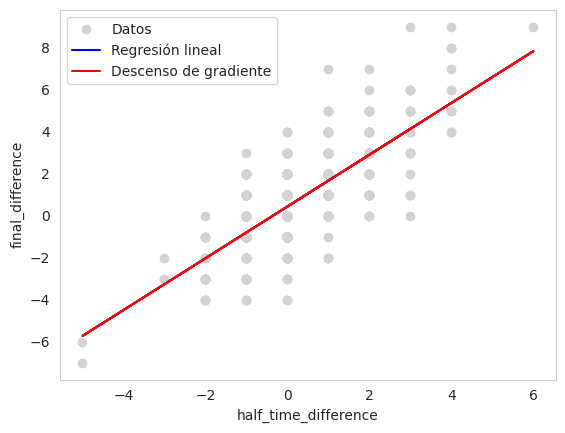

In [ ]:
# Visualizar regresión lineal y perdidas
plt.plot(x, y, 'o', color = 'lightgray', label = 'Datos')
plt.plot(x, beta*x + alpha, color = 'blue', label = 'Regresión lineal')
plt.plot(x, theta_1 * x + theta_0, color = 'red', label = 'Descenso de gradiente')
plt.xlabel('half_time_difference')
plt.ylabel('final_difference')
plt.legend()
plt.grid()
plt.show()

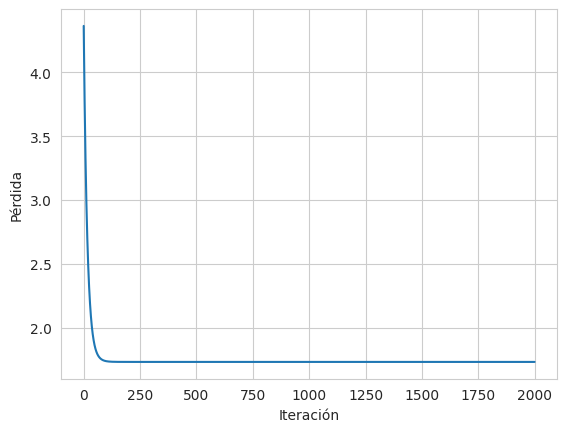

In [ ]:
# Registro final de perdida
plt.plot(perdida)
plt.xlabel('Iteración')
plt.ylabel('Pérdida')
plt.show()

Creamos un gráfico de barras divididas que nos muestra el promedio de goles por país. Esto no da un dato Hungría.

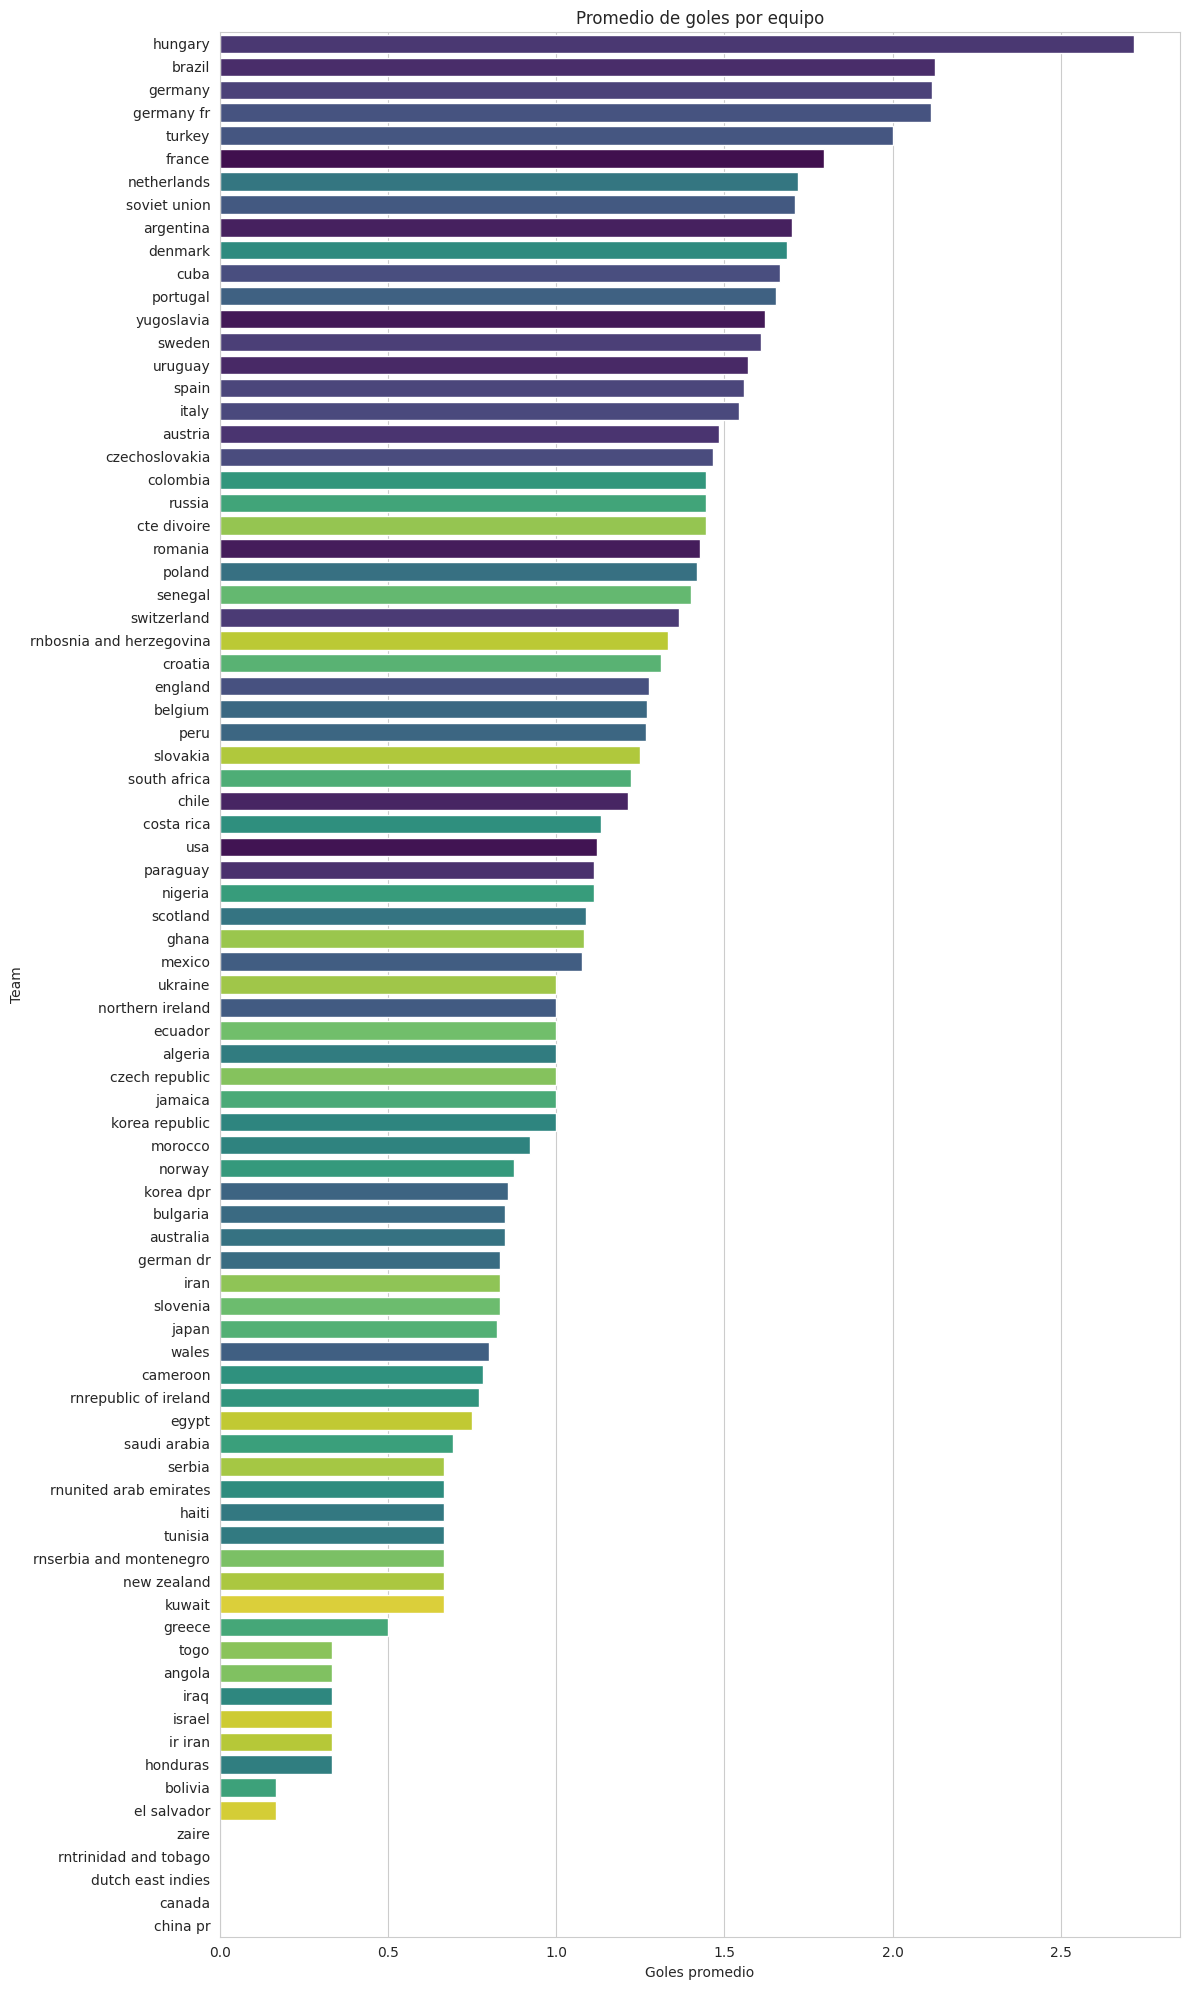

In [ ]:
# Apilamos equipos locales y visitantes en una sola columna para poder graficar todos juntos
df_nuevo = pd.DataFrame({
    'Team': pd.concat([df['Home.Team.Name'], df['Away.Team.Name']], ignore_index=True),
    'Goals': pd.concat([df['Home.Team.Goals'], df['Away.Team.Goals']], ignore_index=True)
})

# Ordenamos de mayor a menor promedio de goles
order = df_nuevo.groupby('Team')['Goals'].mean().sort_values().index[::-1]

plt.figure(figsize=(12, 20))
sns.barplot(data=df_nuevo, x='Goals', y='Team', order=order,
            estimator='mean', palette='viridis', errorbar=None, hue='Team', legend=False)
plt.title('Promedio de goles por equipo')
plt.xlabel('Goles promedio')
plt.tight_layout()
plt.show()

Y de la cantidad de juegos jugados de Hungría, podemos apreciar que el promedio de goles no es una anomalía por tener pocos juegos jugados, ya que tiene más partidos jugados que el promedio.

Promedio de partidos jugados: 20.120481927710845


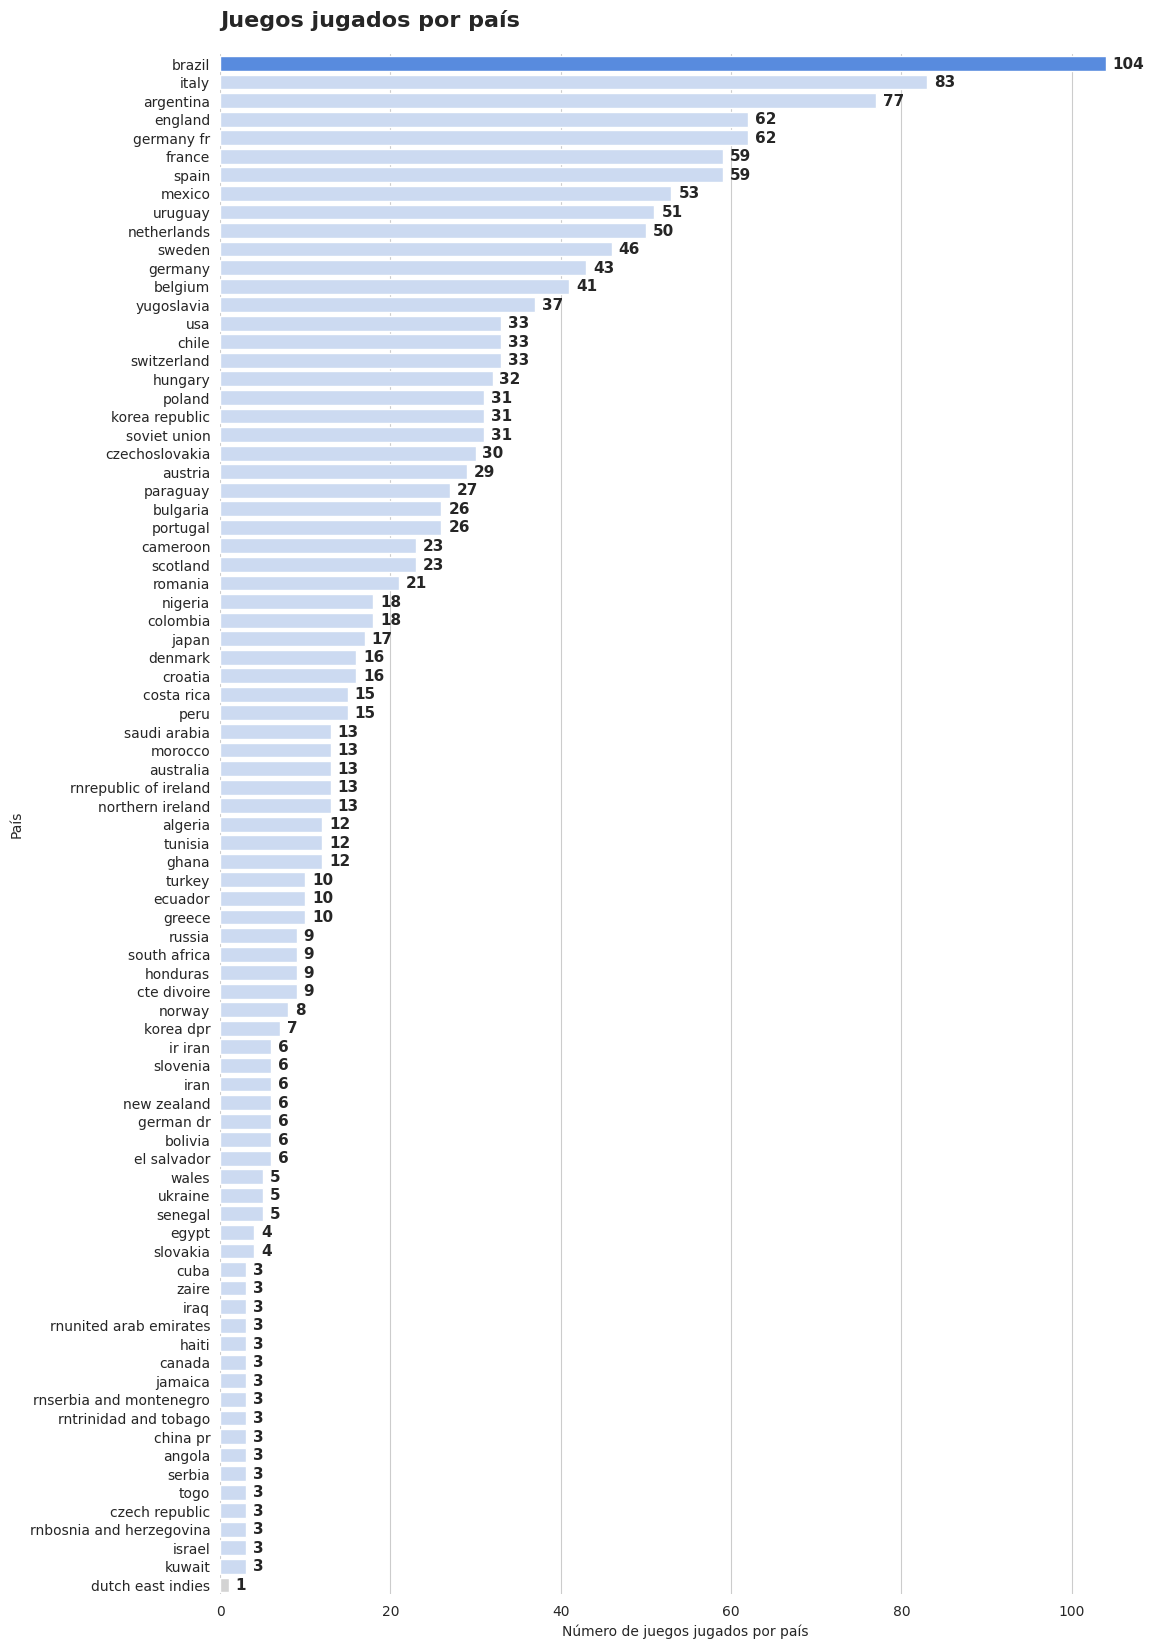

In [ ]:
counts = df_nuevo['Team'].value_counts()
order = counts.index
values = counts.values

print('Promedio de partidos jugados:', sum(values)/len(values))

colors = ['#4285F4' if v == values.max() else '#D3D3D3' if v == values.min() else '#C6D9F7' for v in values]

plt.figure(figsize=(12, 20))
sns.set_style("whitegrid")
ax = sns.barplot(x=values, y=order, palette=colors, hue=order, legend=False)

for p in ax.patches: # Etiquetas de datos
    ax.annotate(f'{int(p.get_width())}',
                (p.get_width(), p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=11, fontweight='bold', xytext=(5, 0), textcoords='offset points')

plt.title('Juegos jugados por país', loc='left', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Número de juegos jugados por país')
plt.ylabel('País')
sns.despine(left=True, bottom=True)
plt.show()

Ahora vemos las gráficas de las asistencias de cada mundial.

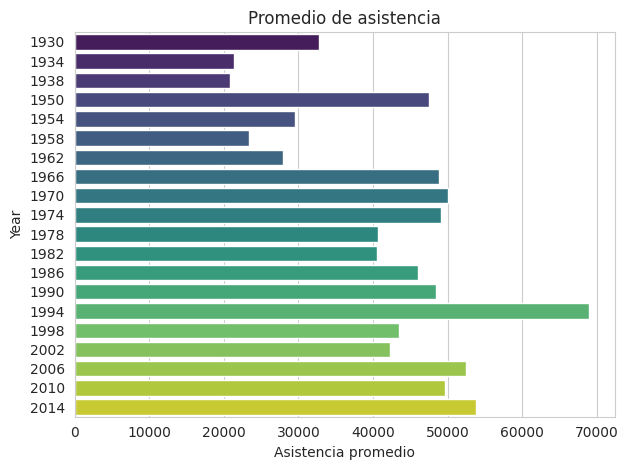

In [ ]:
#plt.figure(figsize=(12, 20))
sns.barplot(data=df_copy, x='Attendance', y='Year',
            estimator='mean', palette='viridis', errorbar=None, hue='Year', legend=False)
plt.title('Promedio de asistencia')
plt.xlabel('Asistencia promedio')

plt.tight_layout()
plt.show()

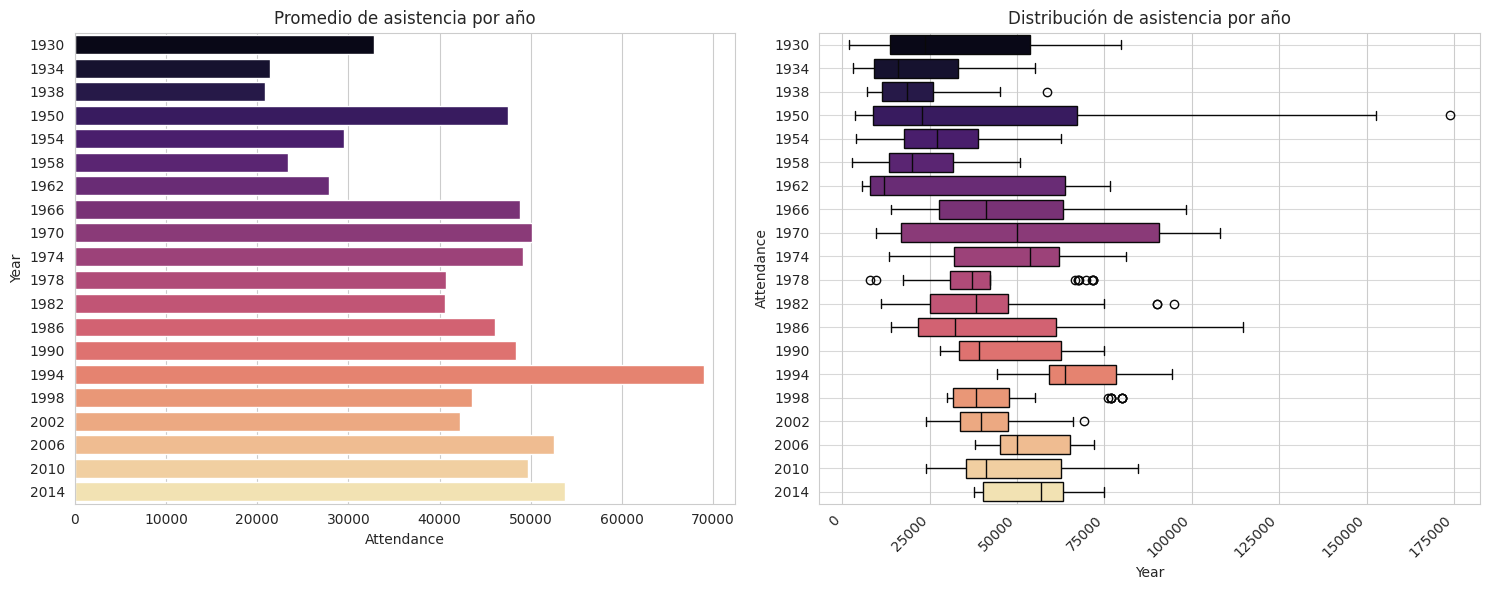

In [ ]:
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
sns.barplot(data=df_copy, x='Attendance', y='Year',
            estimator='mean', palette='magma', errorbar=None, hue='Year', legend=False)
plt.title('Promedio de asistencia por año')
plt.xlabel('Attendance')

plt.subplot(1, 2, 2)
sns.boxplot(data=df_copy, x='Attendance', y='Year', palette='magma', hue='Year', legend=False)
plt.title('Distribución de asistencia por año')
plt.xlabel('Year')
plt.ylabel('Attendance')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.show()

Ahora vemos como le va a cada confederación. Podemos notar que la UEFA es quien más derrotas y victorias tiene, esto por ser la confederación que más equipos lleva a cada edición.

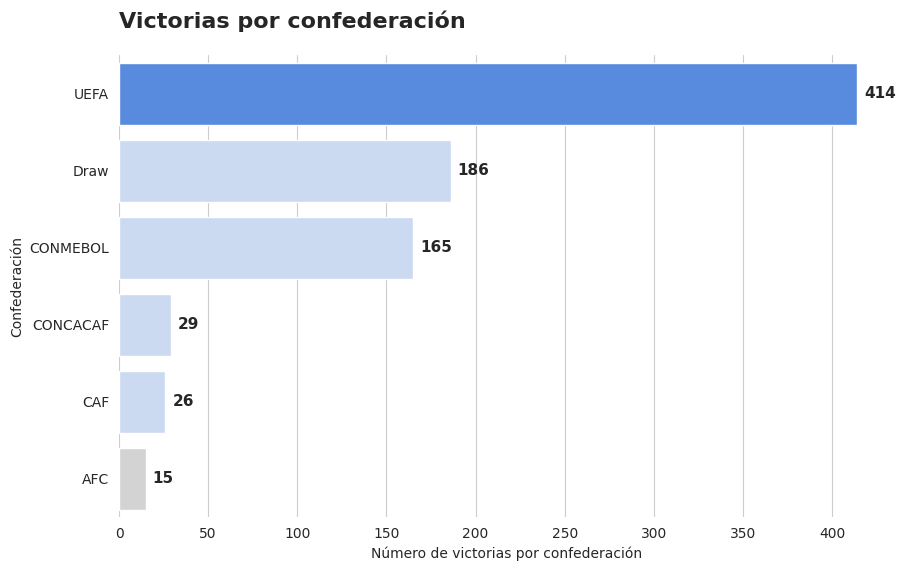

In [ ]:
counts = df_copy['winning_team_confederation'].value_counts()
order = counts.index
values = counts.values

colors = ['#4285F4' if v == values.max() else '#D3D3D3' if v == values.min() else '#C6D9F7' for v in values]

plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")
ax = sns.barplot(x=values, y=order, palette=colors, hue=order, legend=False)

for p in ax.patches: # Etiquetas de datos
    ax.annotate(f'{int(p.get_width())}',
                (p.get_width(), p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=11, fontweight='bold', xytext=(5, 0), textcoords='offset points')

plt.title('Victorias por confederación', loc='left', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Número de victorias por confederación')
plt.ylabel('Confederación')
sns.despine(left=True, bottom=True)
plt.show()

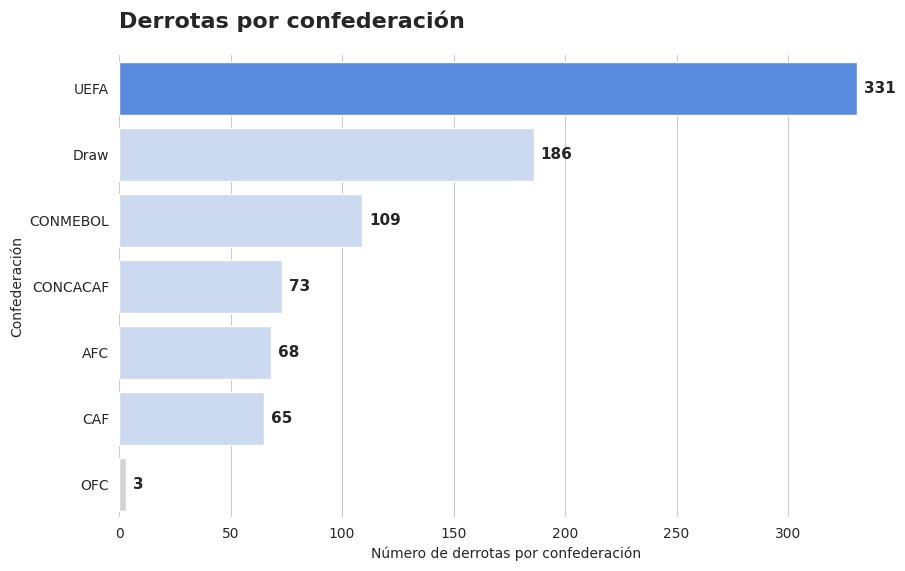

In [ ]:
counts = df_copy['losing_team_confederation'].value_counts()
order = counts.index
values = counts.values

colors = ['#4285F4' if v == values.max() else '#D3D3D3' if v == values.min() else '#C6D9F7' for v in values]

plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")
ax = sns.barplot(x=values, y=order, palette=colors, hue=order, legend=False)

for p in ax.patches: # Etiquetas de datos
    ax.annotate(f'{int(p.get_width())}',
                (p.get_width(), p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=11, fontweight='bold', xytext=(5, 0), textcoords='offset points')

plt.title('Derrotas por confederación', loc='left', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Número de derrotas por confederación')
plt.ylabel('Confederación')
sns.despine(left=True, bottom=True)
plt.show()

Aquí podemos ver que la UEFA gana más contra la mayoría de las confederaciones con excepción de la Conmebol, la Conmebol es la confederación que mejor registro tiene contra las otras confederaciones. Además de que tristemente la OFC no le ha ganado a nadie.

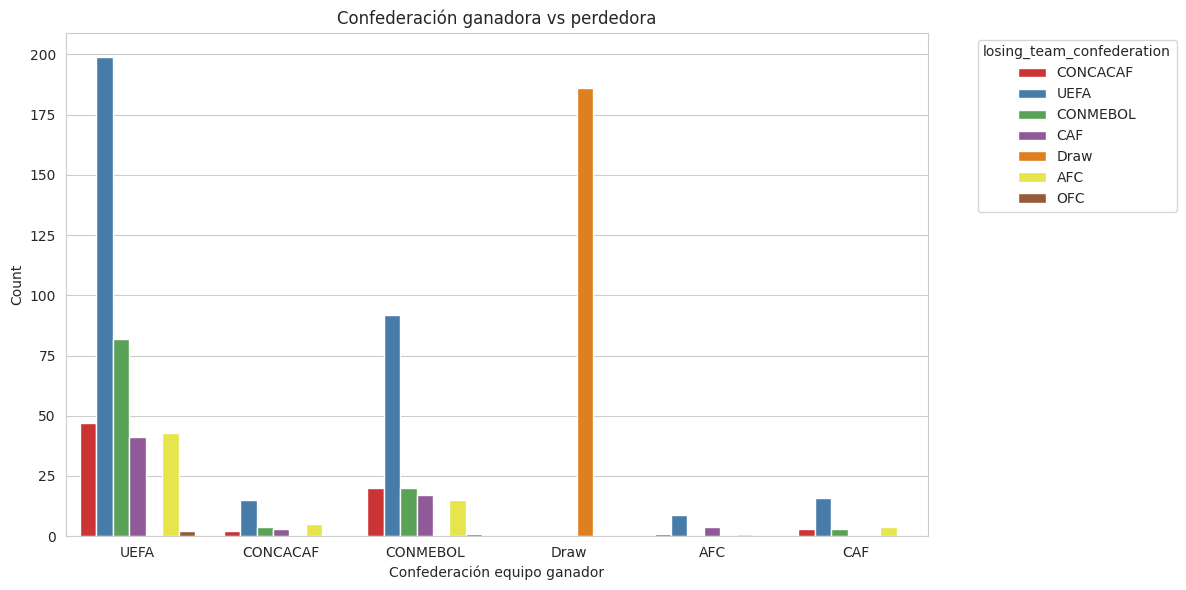

In [ ]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df_copy, x='winning_team_confederation', hue='losing_team_confederation',
              palette='Set1', dodge=True)
plt.title('Confederación ganadora vs perdedora')
plt.xlabel('Confederación equipo ganador')
plt.ylabel('Count')
plt.legend(title='losing_team_confederation', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()